In [1]:
import sys
sys.path.append(r'D:\NUMN32\Adri')
import objects
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import pickle
import glob
from pathlib import Path
import scipy


In [2]:
mu = 100
t0 = 0
y0 = np.array([2,0])
T = 2*mu

In [3]:
eq = objects.vanderPol(t0=0,y0=y0,T=T,mu=mu)
solver = objects.RK34(eq,N=100,adaptative=True)

In [92]:
def vdp_summary(solver: objects.Solver):
    mu = solver.ivp.mu
    y0 = solver.ivp.y0
    
    plt.plot(solver.grid,solver.u[:,1])
    plt.ylabel("$y_2$")
    plt.xlabel("$t$")
    plt.suptitle("van der Pol equation")
    plt.title(rf"$\mu={mu}$")
    plt.show()

    plt.scatter(y0[0],y0[1],label=r"$y(0)$",color="red")
    plt.plot(solver.u[:,0],solver.u[:,1])
    plt.ylabel("$y_2$")
    plt.xlabel("$y_1$")
    plt.suptitle("phase space")
    plt.title(rf"$\mu={mu}$")
    plt.legend()
    plt.show()

    plt.semilogy(solver.grid[:-1], np.diff(solver.grid))
    plt.title("Adaptative RK34 step size")
    plt.xlabel(r"$t$")
    plt.ylabel(r"$\Delta t$")
    plt.show()

In [77]:
solver.N

14598

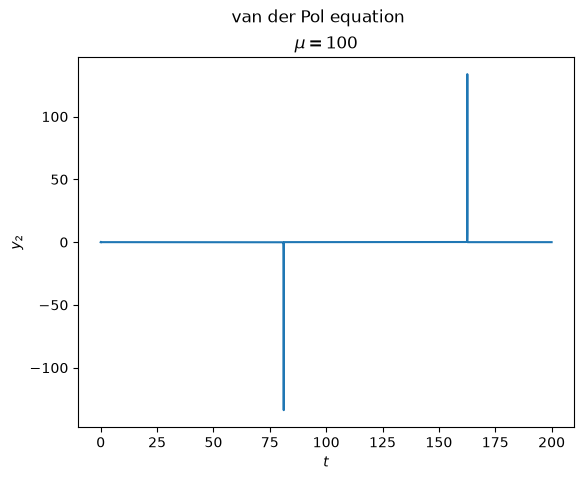

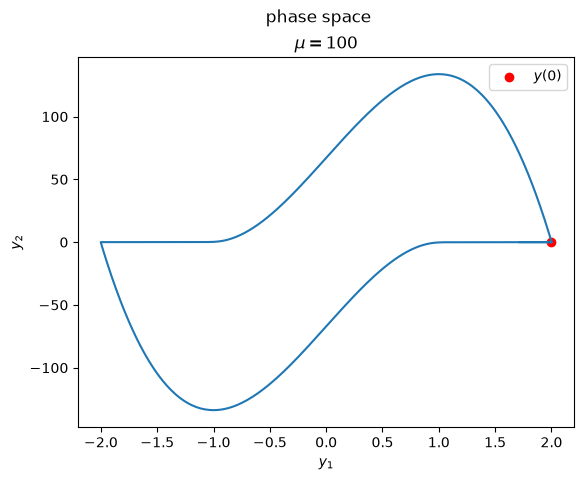

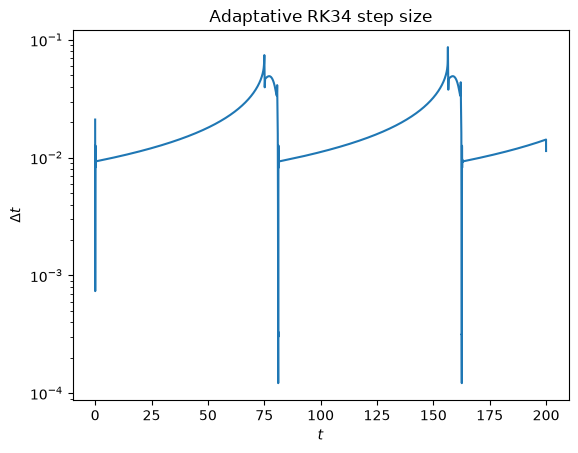

In [86]:
vdp_summary(solver)

In [ ]:
series = [10,15,22,33,47,68,100,150,220,330,470,680,1000]
def E6_solver(mu):
    t0 = 0
    y0 = np.array([2,0])
    T = 0.7*mu
    eq = objects.vanderPol(t0=t0,y0=y0,T=T,mu=mu)
    solver = objects.RK34(eq,N=100,adaptative=True,tol=1e-8)
    solver.integrate()
    return solver


In [110]:
solvers = []
for mu in tqdm(series):
    solvers.append(E6_solver(mu))

100%|██████████| 13/13 [17:33<00:00, 81.07s/it] 


In [ ]:
#save solvers
for solver in solvers:
    file = "E6\\"+str(solver.ivp.mu)+".pkl"
    pickle.dump(solver,open(file,"wb"))

In [127]:
load_solvers = []
files = sorted(Path("E6").glob("*.pkl"), key=lambda p: int(p.stem))
for rute in files:
    load_solvers.append(pickle.load(open(rute,"rb")))

In [187]:
steps = []
mu = []

for solver in load_solvers:
    steps.append(solver.N)
    mu.append(solver.ivp.mu)

Text(0, 0.5, 'N')

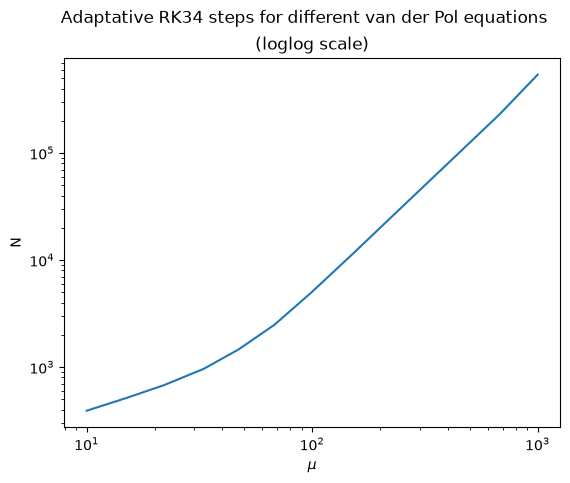

In [189]:
plt.loglog(mu,steps)
plt.suptitle("Adaptative RK34 steps for different van der Pol equations")
plt.title("(loglog scale)")
plt.xlabel(rf"$\mu$")
plt.ylabel(rf"N")

In [169]:
def E6_solver_scipy(mu,method):
    t0 = 0
    y0 = np.array([2,0])
    T = 0.7*mu
    eq = objects.vanderPol(t0=t0,y0=y0,T=T,mu=mu)
    solver = scipy.integrate.solve_ivp(fun=eq.f,y0=y0,t_span=(t0,T),method=method)
    return solver

In [172]:
BDF_solvers = {}
for mu in tqdm(series):
    BDF_solvers[mu] = E6_solver_scipy(mu,"BDF")

100%|██████████| 13/13 [00:00<00:00, 87.22it/s]


Text(0, 0.5, 'N')

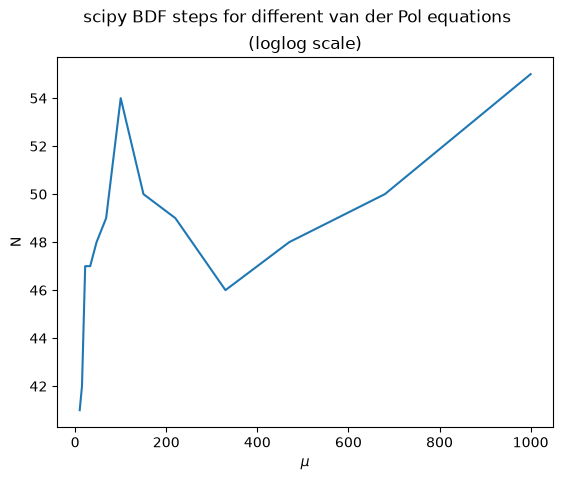

In [190]:
mus = BDF_solvers.keys()
Ns = [ len(BDF_solvers[mu].t) for mu in mus]
plt.plot(mus,Ns)
plt.suptitle("scipy BDF steps for different van der Pol equations")
plt.title("(loglog scale)")
plt.xlabel(rf"$\mu$")
plt.ylabel(rf"N")

In [191]:
RK45_solvers = {}
for mu in tqdm(series):
    BDF_solvers[mu] = E6_solver_scipy(mu,"RK45")

100%|██████████| 13/13 [00:54<00:00,  4.17s/it]
